# 02 · Cell states (Fig 1C)

Groups the units of notebook 01 (257 mouse SMCs, 147 rabbit metacells) into 40 transcriptional states per species,
matches the states across species, and draws the expression heatmap of Fig 1C.

1. **Expression**: log2(UMI fraction + 10⁻⁵) of each SMC and rabbit RNA metacell, centred per gene over all units of
   the species.
2. **States**: Pearson correlation between mouse SMCs and rabbit metacells over the 655 feature genes the two metacell
   models share; the units of each species are clustered on their correlation profiles (Ward) and cut into 40 states.
3. **Homologous states**: each unit's top-5 correlated units of the other species; reciprocal matches are counted per
   pair of states, and pairs of states that are each other's best (most matches) are the 24 homologous states.
4. **Fig 1C**: expression of 41 lineage genes in the SMCs and metacells, interleaved by cell type.

## Setup

In [1]:
source("../R/setup.R")
source("../R/cell_types.R")
suppressPackageStartupMessages(library(ComplexHeatmap))
ht_opt$message = FALSE
out_dir = out_path("02_states")
units = fread(file.path(OUT_DIR, "01_crecls", "units.csv"))

Cell types of the units, as in notebook 01. The units are taken in cell-type order, the column order of the source's
CRECl matrices (`mm_ord_clmc`, `oc_ord_clmc`); the state clustering below depends on it.

In [2]:
mc_type_mm = fread(data_path("mc_type_mm_2025.csv"))
mc_type_oc = fread(data_path("metacell_types-2024-12-04.csv")) %>%
    mutate(metacell = gsub(".[0-9]+$", "", gsub("^M", "mc", metacell))) %>%
    filter(color %in% oc_type_colors) %>%
    arrange(match(color, oc_type_colors))
smc_type_mm = with(distinct(mc_type_mm, smc, smc_type), setNames(smc_type, smc))
oc_idx2sh = setNames(mc_type_oc$cell_type, mc_type_oc$metacell)
mc_type_mm = mc_type_mm %>% filter(color %in% mm_type_colors) %>% arrange(match(color, mm_type_colors))
mm_col_order = unique(mc_type_mm$cell_type)
oc_col_order = unique(mc_type_oc$cell_type)
mm_code_color = with(distinct(mc_type_mm, cell_type, color), setNames(color, cell_type))
oc_code_color = with(distinct(mc_type_oc, cell_type, color), setNames(color, cell_type))

mm_units = units %>% filter(species == "mouse", used) %>% pull(unit)
oc_units = units %>% filter(species == "rabbit", used) %>% pull(unit)
mm_units = mm_units[order(match(smc_type_mm[mm_units], mm_col_order))]
oc_units = oc_units[order(match(oc_idx2sh[oc_units], oc_col_order))]

## 1. Expression

Mouse UMIs are summed per SMC (all 300), rabbit UMIs are those of the 257 rabbit RNA metacells. The feature genes are
the genes each metacell model selected as markers, without its lateral genes; 655 of them are shared.

In [3]:
mm_smc_rna_sum = fread(data_path("mm_smc_rna_sum.csv"))
rownames(mm_smc_rna_sum) = 1:300
colnames(mm_smc_rna_sum) = toupper(colnames(mm_smc_rna_sum))
oc_mc_rna_sum = as.matrix(fread(data_path("oc_mc_rna_umis.csv")) %>% column_to_rownames("metacell"))
rownames(oc_mc_rna_sum) = gsub(".[0-9]+$", "", gsub("^M", "mc", rownames(oc_mc_rna_sum)))
mm_gset = fread(data_path("mm_rna_genes.csv")) %>% filter(selected_gene, marker_gene, !lateral_gene) %>% pull(gene)
oc_gset = fread(data_path("oc_rna_genes.csv")) %>% filter(selected_gene, marker_gene, !lateral_gene) %>% pull(gene)
inter_gset = intersect(toupper(mm_gset), oc_gset)

mm_smc_mean_egc = mm_smc_rna_sum/rowSums(mm_smc_rna_sum)
oc_mc_egc = oc_mc_rna_sum/rowSums(oc_mc_rna_sum)
mm_legc = log2(1e-5+t(mm_smc_mean_egc))
oc_legc = log2(1e-5+t(oc_mc_egc))
colnames(mm_legc) = 1:300
mm_legcn = mm_legc - apply(mm_legc,1,mean)
oc_legcn = oc_legc - apply(oc_legc,1,mean)

## 2. States

`cutree` numbers the clusters in the order of the units, so the state names (MM1-MM40, OC1-OC40) are those of the paper
only with the unit order above. A state's type is the atlas type of most of its units (mouse: of its metacells), ties
going to the type first in alphabetical order.

In [4]:
cross_corn = tgs_cor(mm_legcn[inter_gset,], oc_legcn[inter_gset,])[mm_units, oc_units]
oc_hc = hclust(tgs_dist(t(cross_corn)), "ward.D2")
mm_hc = hclust(tgs_dist(cross_corn), "ward.D2")
k_clust = 40
oc_sup = cutree(oc_hc, k_clust)
oc_sup = setNames(paste0("OC", oc_sup), names(oc_sup))
mm_sup = cutree(mm_hc, k_clust)
mm_sup = setNames(paste0("MM", mm_sup), names(mm_sup))
mc_type_mm$sup = mm_sup[as.character(mc_type_mm$smc)]
mc_type_oc$sup = oc_sup[mc_type_oc$metacell]

mm_mclst_types_n = table(mc_type_mm %>% select(sup, cell_type))
mm_mclst_type = setNames(colnames(mm_mclst_types_n)[apply(mm_mclst_types_n, 1, which.max)], rownames(mm_mclst_types_n))
oc_mclst_types_n = table(oc_sup, oc_idx2sh[names(oc_sup)])
oc_mclst_type = setNames(colnames(oc_mclst_types_n)[apply(oc_mclst_types_n, 1, which.max)], rownames(oc_mclst_types_n))

## 3. Homologous states

The state-by-state matrix of mean correlations (`cor_mean_mean`), in cell-type order, fixes the order in which ties
between equally matched states are resolved (`slice_max(with_ties = FALSE)` keeps the first).

In [5]:
long_mm_ocf_cors = as.data.frame(cross_corn) %>%
    rownames_to_column("mouse_mc") %>%
    pivot_longer(cols = colnames(cross_corn), names_to = "rabbit_mc", values_to = "cor")
long_mm_ocf_cors_colored = long_mm_ocf_cors %>%
    left_join(enframe(oc_idx2sh) %>% rename(rabbit_mc = name, rabbit_col = value), by = "rabbit_mc") %>%
    left_join(enframe(smc_type_mm) %>% rename(mouse_mc = name, mouse_col = value), by = "mouse_mc")
tmp_rabbit = long_mm_ocf_cors_colored %>% group_by(rabbit_mc) %>% top_n(5, cor) %>% ungroup()
tmp_mouse = long_mm_ocf_cors_colored %>% group_by(mouse_mc) %>% top_n(5, cor) %>% ungroup()
rboms = intersect(tmp_rabbit, tmp_mouse)

mm_cor_mean = tgs_matrix_tapply(t(cross_corn), mm_sup, mean)
cor_mean_mean = tgs_matrix_tapply(mm_cor_mean, oc_sup, mean)
cor_mean_mean = cor_mean_mean[order(match(oc_mclst_type, oc_col_order)), order(match(mm_mclst_type, mm_col_order))]

sup_sup_rboms = enframe(mm_sup) %>%
    rename(mouse_mc = name, mm_sup = value) %>%
    mutate(mm_sup = factor(mm_sup, levels = paste0("MM", 1:40))) %>%
    left_join(
        enframe(oc_sup) %>%
            rename(rabbit_mc = name, oc_sup = value) %>%
            mutate(oc_sup = factor(oc_sup, levels = paste0("OC", 1:40))) %>%
            left_join(rboms, by = "rabbit_mc"),
        by = "mouse_mc"
    ) %>%
    group_by(mm_sup, oc_sup) %>%
    summarise(nrboms = sum(!is.na(cor)), .groups = "keep") %>%
    filter(!is.na(oc_sup)) %>%
    pivot_wider(names_from = "oc_sup", values_from = "nrboms", values_fill = 0) %>%
    column_to_rownames("mm_sup")
extras = sup_sup_rboms[1:length(setdiff(paste0("MM", 1:40), rownames(sup_sup_rboms))),]
extras[1:length(setdiff(paste0("MM", 1:40), rownames(sup_sup_rboms))),] = 0
rownames(extras) = setdiff(paste0("MM", 1:40), rownames(sup_sup_rboms))
sup_sup_rboms = rbind(sup_sup_rboms, extras)

sup_sup_rboms_reord = t(sup_sup_rboms[
    intersect(colnames(cor_mean_mean), rownames(sup_sup_rboms)),
    intersect(rownames(cor_mean_mean), colnames(sup_sup_rboms))
])
long_sup_sup_rboms = as.data.frame(sup_sup_rboms_reord) %>%
    rownames_to_column("rabbit_mcc") %>%
    pivot_longer(cols = colnames(sup_sup_rboms_reord), names_to = "mouse_mcc", values_to = "nrbom")
tmp_rabbit = long_sup_sup_rboms %>% group_by(rabbit_mcc) %>% slice_max(nrbom, n = 1, with_ties = F) %>% ungroup()
tmp_mouse = long_sup_sup_rboms %>% group_by(mouse_mcc) %>% slice_max(nrbom, n = 1, with_ties = F) %>% ungroup()
rbomcs = intersect(tmp_rabbit, tmp_mouse)

## 4. Fig 1C

The 43 genes of the figure that are named the same in both species (41; PASD1 and T, rabbit TBXT, drop out), as
log2 expression centred per gene. Rows are ordered by the mouse SMC of highest expression; columns interleave the
mouse SMCs and rabbit metacells by cell type (`joint_type_colors`, `R/cell_types.R`).

In [6]:
heatmap_genes = c("PASD1", "TFAP2C", "WNT6", "SOX10", "DLX5", "TFAP2A", "OTX2", "SOX2", "POU5F1", "NANOG", "TDGF1",
    "EOMES", "MIXL1", "T", "MSGN1", "CDX1", "NKX1-2", "CDX2", "RSPO3", "OSR1", "FOXC1", "TCF15", "RIPPLY1", "MEOX1",
    "SFRP5", "TNNI1", "FOXF1", "HAND1", "DLK1", "ITGA4", "CDH5", "CD93", "LMO2", "TAL1", "ETV2", "GATA1", "GYPA",
    "NOTO", "LHX1", "FOXA2", "SOX17", "APOE", "FOXA1")
common_heatmap_genes = intersect(intersect(heatmap_genes, rownames(mm_legcn)), rownames(oc_legcn))
common_rbog_tfs = intersect(intersect(rownames(mm_legc), common_heatmap_genes), rownames(oc_legc))
mm_markers_heatmap = mm_legcn[common_rbog_tfs, mm_units]
mm_markers_heatmap = mm_markers_heatmap[order(apply(mm_markers_heatmap, 1, which.max)),]
oc_markers_heatmap = oc_legcn[rownames(mm_markers_heatmap), oc_units]

mm_anno = smc_type_mm[colnames(mm_markers_heatmap)]
oc_anno = oc_idx2sh[colnames(oc_markers_heatmap)]
all_code_color = c(mm_code_color, oc_code_color)
get_hex_safely = function(anno_vals, color_map) {
    hexes = color_map[anno_vals]
    hexes[is.na(hexes)] = anno_vals[is.na(hexes)]
    toupper(as.character(hexes))
}
df_cols = data.frame(
    colname = c(colnames(mm_markers_heatmap), colnames(oc_markers_heatmap)),
    dataset = rep(c("mm", "oc"), times = c(ncol(mm_markers_heatmap), ncol(oc_markers_heatmap))),
    hex = c(get_hex_safely(mm_anno, all_code_color), get_hex_safely(oc_anno, all_code_color)),
    stringsAsFactors = FALSE
)
df_cols$hex_factor = factor(df_cols$hex, levels = joint_type_colors)
interleaved_cols = df_cols[order(df_cols$hex_factor, df_cols$dataset, na.last = TRUE), "colname"]
combined_mat_ordered = cbind(mm_markers_heatmap, oc_markers_heatmap)[, interleaved_cols, drop = FALSE]
all_class = c(mm_anno, oc_anno)
anno_col_ordered = data.frame(
    color = all_class[interleaved_cols],
    dataset = ifelse(interleaved_cols %in% colnames(mm_markers_heatmap), "mm", "oc"),
    row.names = interleaved_cols
)

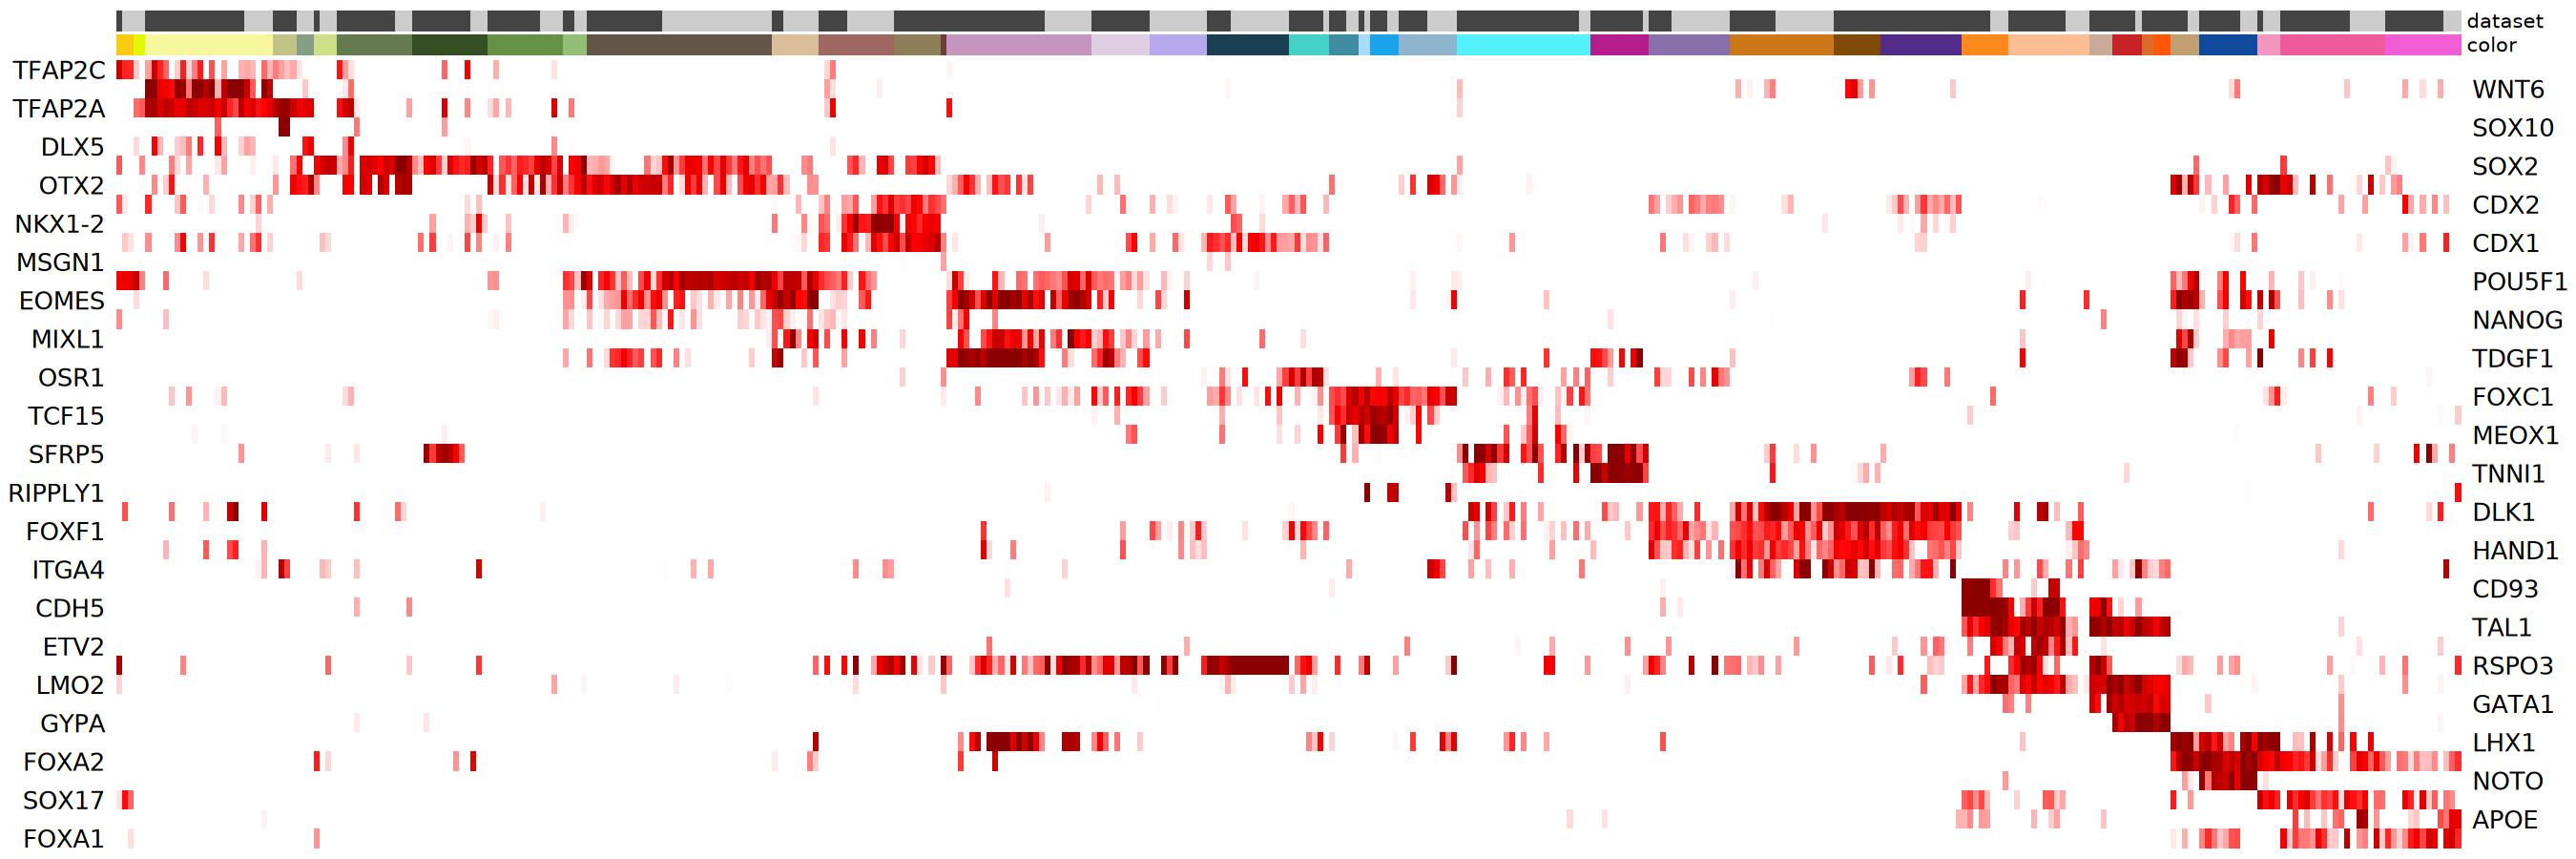

In [7]:
rn = rownames(combined_mat_ordered)
ha_left = rowAnnotation(left_labels = anno_text(ifelse(seq_along(rn) %% 2 != 0, rn, ""), just = "right", location = unit(1, "npc")))
ha_right = rowAnnotation(right_labels = anno_text(ifelse(seq_along(rn) %% 2 == 0, rn, ""), just = "left", location = unit(0, "npc")))
abs_shades = colorRampPalette(c("white", "red", "darkred"))(1000)
ht = ComplexHeatmap::pheatmap(
    mat = combined_mat_ordered, legend = FALSE, annotation_legend = FALSE, show_colnames = FALSE, show_rownames = FALSE,
    cluster_cols = FALSE, cluster_rows = FALSE, col = abs_shades, breaks = c(-4, seq(1, 4, l = 999), 5),
    annotation_col = anno_col_ordered,
    annotation_colors = list(color = all_code_color, dataset = c(mm = "#444444", oc = "#CCCCCC"))
)
options(repr.plot.width = 18, repr.plot.height = 6)
draw(ha_left + ht + ha_right)

## Outputs

For the later notebooks: the mouse metacells with their state (`mc_type_mm_smc_sup.csv`) and the states, their types and
the homologous states (`states.rds`).

In [8]:
fwrite(mc_type_mm, file.path(out_dir, "mc_type_mm_smc_sup.csv"))
saveRDS(list(mm_sup = mm_sup, oc_sup = oc_sup, mm_mclst_type = mm_mclst_type, oc_mclst_type = oc_mclst_type, rbomcs = rbomcs),
        file.path(out_dir, "states.rds"))